In [1]:
import os
import shutil
import random

#  CHANGE ONLY THIS (where your raw folders are)
RAW_BASE = r"C:\Users\ashuz\OneDrive\Desktop\Colon cancer\Colon_Cancer_Data\ZIP_Colon_Cancer_Data\Unzip_Colon_Cancer_Data"

POS_FOLDERS = [
    "sundatabase_positive_part1",
    "sundatabase_positive_part2"
]

NEG_FOLDERS = [
    "sundatabase_negative_part1",
    "sundatabase_negative_part2",
    "sundatabase_negative_part3",
    "sundatabase_negative_part4"
]

# Output dataset
OUT_BASE = r"C:\Users\ashuz\Desktop\GI_Endoscopy_Q1"

splits = {
    "train": 0.7,
    "val": 0.15,
    "test": 0.15
}

def collect_images(folder_list):
    images = []
    for folder in folder_list:
        folder_path = os.path.join(RAW_BASE, folder)
        for img in os.listdir(folder_path):
            if img.lower().endswith((".jpg", ".png", ".jpeg")):
                images.append(os.path.join(folder_path, img))
    return images

pos_images = collect_images(POS_FOLDERS)
neg_images = collect_images(NEG_FOLDERS)

random.shuffle(pos_images)
random.shuffle(neg_images)

def split_and_copy(images, label):
    n = len(images)
    t_end = int(splits["train"] * n)
    v_end = t_end + int(splits["val"] * n)

    split_sets = {
        "train": images[:t_end],
        "val": images[t_end:v_end],
        "test": images[v_end:]
    }

    for split, imgs in split_sets.items():
        out_dir = os.path.join(OUT_BASE, split, label)
        os.makedirs(out_dir, exist_ok=True)
        for img in imgs:
            shutil.copy(img, out_dir)

split_and_copy(pos_images, "positive")
split_and_copy(neg_images, "negative")

print("✅ Dataset prepared successfully for Q1 experiments")


✅ Dataset prepared successfully for Q1 experiments


STEP 2: VERIFY DATASET

In [2]:
import os
import shutil
import random

RAW_BASE = r"C:\Users\ashuz\OneDrive\Desktop\Colon cancer\Colon_Cancer_Data\ZIP_Colon_Cancer_Data\Unzip_Colon_Cancer_Data"   # parent folder where sundatabase_* folders exist
OUT_BASE = r"C:\Users\ashuz\Desktop\GI_Endoscopy_Q1"

POS_FOLDERS = [
    "sundatabase_positive_part1",
    "sundatabase_positive_part2"
]

NEG_FOLDERS = [
    "sundatabase_negative_part1",
    "sundatabase_negative_part2",
    "sundatabase_negative_part3",
    "sundatabase_negative_part4"
]


COLLECT ALL IMAGES (CASE-WISE SAFE)

In [3]:
def collect_images(folder_list):
    images = []
    for folder in folder_list:
        folder_path = os.path.join(RAW_BASE, folder)
        if not os.path.exists(folder_path):
            print("❌ Not found:", folder_path)
            continue

        for root, _, files in os.walk(folder_path):
            for f in files:
                if f.lower().endswith((".jpg", ".jpeg", ".png")):
                    images.append(os.path.join(root, f))
    return images

pos_images = collect_images(POS_FOLDERS)
neg_images = collect_images(NEG_FOLDERS)

print("✅ Positive images:", len(pos_images))
print("✅ Negative images:", len(neg_images))


✅ Positive images: 49136
✅ Negative images: 109554


TRAIN / VAL / TEST SPLIT (70 / 15 / 15)

In [4]:
import os
import shutil
import uuid

def split_and_copy(images, label):
    n = len(images)
    train_end = int(0.7 * n)
    val_end = int(0.85 * n)

    splits = {
        "train": images[:train_end],
        "val": images[train_end:val_end],
        "test": images[val_end:]
    }

    for split, imgs in splits.items():
        out_dir = os.path.join(OUT_BASE, split, label)
        os.makedirs(out_dir, exist_ok=True)

        for img in imgs:
            ext = os.path.splitext(img)[1]
            new_name = f"{label}_{uuid.uuid4().hex}{ext}"
            dst = os.path.join(out_dir, new_name)
            shutil.move(img, dst)


In [5]:
import os

BASE_DIR = r"C:\Users\ashuz\Desktop\GI_Endoscopy_Q1"

for split in ["train", "val", "test"]:
    for cls in ["positive", "negative"]:
        path = os.path.join(BASE_DIR, split, cls)
        print(f"{split}/{cls} ->", len(os.listdir(path)))


train/positive -> 37324
train/negative -> 17223
val/positive -> 7370
val/negative -> 8960
test/positive -> 7371
test/negative -> 8961


In [6]:
import os
import random
import shutil

BASE_DIR = r"C:\Users\ashuz\Desktop\GI_Endoscopy_Q1"

neg_train_dir = os.path.join(BASE_DIR, "train", "negative")
neg_val_dir   = os.path.join(BASE_DIR, "val", "negative")
neg_test_dir  = os.path.join(BASE_DIR, "test", "negative")

neg_images = os.listdir(neg_train_dir)
print("Total negative images (train):", len(neg_images)) 



Total negative images (train): 17223


In [7]:
random.shuffle(neg_images)

n = len(neg_images)
val_count  = int(0.15 * n)
test_count = int(0.15 * n)

val_imgs  = neg_images[:val_count]
test_imgs = neg_images[val_count:val_count + test_count]

os.makedirs(neg_val_dir, exist_ok=True)
os.makedirs(neg_test_dir, exist_ok=True)

for img in val_imgs:
    shutil.move(
        os.path.join(neg_train_dir, img),
        os.path.join(neg_val_dir, img)
    )

for img in test_imgs:
    shutil.move(
        os.path.join(neg_train_dir, img),
        os.path.join(neg_test_dir, img)
    )

print("✅ Negative class re-balanced")


✅ Negative class re-balanced


In [8]:
for split in ["train", "val", "test"]:
    for cls in ["positive", "negative"]:
        path = os.path.join(BASE_DIR, split, cls)
        print(f"{split}/{cls} ->", len(os.listdir(path)))


train/positive -> 37324
train/negative -> 12057
val/positive -> 7370
val/negative -> 11543
test/positive -> 7371
test/negative -> 11544


PREPARE IMAGE GENERATORS

In [9]:
import os
from tensorflow.keras.preprocessing.image import ImageDataGenerator

BASE_DIR = r"C:\Users\ashuz\Desktop\GI_Endoscopy_Q1"

IMG_SIZE = (224, 224)
BATCH_SIZE = 16

train_datagen = ImageDataGenerator(
    rescale=1./255,
    rotation_range=20,
    zoom_range=0.2,
    horizontal_flip=True
)

val_test_datagen = ImageDataGenerator(rescale=1./255)

train_gen = train_datagen.flow_from_directory(
    os.path.join(BASE_DIR, "train"),
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode="binary"
)

val_gen = val_test_datagen.flow_from_directory(
    os.path.join(BASE_DIR, "val"),
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode="binary"
)

test_gen = val_test_datagen.flow_from_directory(
    os.path.join(BASE_DIR, "test"),
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode="binary",
    shuffle=False
)


Found 49381 images belonging to 2 classes.
Found 18913 images belonging to 2 classes.
Found 18915 images belonging to 2 classes.


In [10]:
from tensorflow.keras.applications import VGG16
from tensorflow.keras.layers import Dense, GlobalAveragePooling2D
from tensorflow.keras.models import Model
from tensorflow.keras.optimizers import Adam

base_model = VGG16(
    weights="imagenet",
    include_top=False,
    input_shape=(224,224,3)
)

for layer in base_model.layers:
    layer.trainable = False

x = GlobalAveragePooling2D()(base_model.output)
x = Dense(256, activation="relu")(x)
output = Dense(1, activation="sigmoid")(x)

model_vgg = Model(base_model.input, output)

model_vgg.compile(
    optimizer=Adam(1e-4),
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

model_vgg.summary()


Model: "model"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 input_1 (InputLayer)        [(None, 224, 224, 3)]     0         
                                                                 
 block1_conv1 (Conv2D)       (None, 224, 224, 64)      1792      
                                                                 
 block1_conv2 (Conv2D)       (None, 224, 224, 64)      36928     
                                                                 
 block1_pool (MaxPooling2D)  (None, 112, 112, 64)      0         
                                                                 
 block2_conv1 (Conv2D)       (None, 112, 112, 128)     73856     
                                                                 
 block2_conv2 (Conv2D)       (None, 112, 112, 128)     147584    
                                                                 
 block2_pool (MaxPooling2D)  (None, 56, 56, 128)       0     

In [11]:
import os
import tensorflow as tf
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.applications import VGG16, ResNet50
from tensorflow.keras.layers import Dense, GlobalAveragePooling2D, Dropout
from tensorflow.keras.models import Model
from tensorflow.keras.optimizers import Adam


In [12]:
BASE_DIR = r"C:\Users\ashuz\Desktop\GI_Endoscopy_Q1"

IMG_SIZE = (224,224)
BATCH_SIZE = 16

train_datagen = ImageDataGenerator(
    rescale=1./255,
    rotation_range=20,
    zoom_range=0.2,
    horizontal_flip=True
)

val_test_datagen = ImageDataGenerator(rescale=1./255)

train_gen = train_datagen.flow_from_directory(
    os.path.join(BASE_DIR, "train"),
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode="binary"
)

val_gen = val_test_datagen.flow_from_directory(
    os.path.join(BASE_DIR, "val"),
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode="binary"
)


Found 49381 images belonging to 2 classes.
Found 18913 images belonging to 2 classes.


In [13]:
base_model = ResNet50(
    weights="imagenet",
    include_top=False,
    input_shape=(224,224,3)
)

for layer in base_model.layers:
    layer.trainable = False

x = GlobalAveragePooling2D()(base_model.output)
x = Dense(256, activation="relu")(x)
x = Dropout(0.5)(x)
output = Dense(1, activation="sigmoid")(x)

model_resnet = Model(base_model.input, output)

model_resnet.compile(
    optimizer=Adam(1e-4),
    loss="binary_crossentropy",
    metrics=["accuracy"]
)


Checks every image / Removes corrupted / non-image files

In [40]:
from PIL import Image
import os

def clean_image_folder(folder_path):
    bad_files = 0
    for root, _, files in os.walk(folder_path):
        for file in files:
            file_path = os.path.join(root, file)
            try:
                img = Image.open(file_path)
                img.verify()   # verify image integrity
            except Exception:
                bad_files += 1
                os.remove(file_path)
                print(f"❌ Removed corrupt file: {file_path}")
    print(f"✅ Cleaning done for {folder_path}. Bad files removed: {bad_files}")

BASE_DIR = r"C:\Users\ashuz\Desktop\GI_Endoscopy_Q1"

clean_image_folder(os.path.join(BASE_DIR, "train"))
clean_image_folder(os.path.join(BASE_DIR, "val"))
clean_image_folder(os.path.join(BASE_DIR, "test"))


❌ Removed corrupt file: C:\Users\ashuz\Desktop\GI_Endoscopy_Q1\train\positive\case_M_20181105095958_0U62368110576557_1_003_002-1_a7_ayy_image0070.jpg
✅ Cleaning done for C:\Users\ashuz\Desktop\GI_Endoscopy_Q1\train. Bad files removed: 1
❌ Removed corrupt file: C:\Users\ashuz\Desktop\GI_Endoscopy_Q1\val\negative\case_M_20181109094641_0U62372110931241_1_003_001-1_Negative_ayy_image006988.jpg
✅ Cleaning done for C:\Users\ashuz\Desktop\GI_Endoscopy_Q1\val. Bad files removed: 1
✅ Cleaning done for C:\Users\ashuz\Desktop\GI_Endoscopy_Q1\test. Bad files removed: 0


RECHECK FINAL IMAGE COUNTS

In [41]:
def count_images(path):
    for cls in ["positive", "negative"]:
        folder = os.path.join(path, cls)
        count = len(os.listdir(folder)) if os.path.exists(folder) else 0
        print(f"{path}/{cls} -> {count}")

BASE_DIR = r"C:\Users\ashuz\Desktop\GI_Endoscopy_Q1"

print("TRAIN:")
count_images(os.path.join(BASE_DIR, "train"))

print("\nVAL:")
count_images(os.path.join(BASE_DIR, "val"))

print("\nTEST:")
count_images(os.path.join(BASE_DIR, "test"))


TRAIN:
C:\Users\ashuz\Desktop\GI_Endoscopy_Q1\train/positive -> 37324
C:\Users\ashuz\Desktop\GI_Endoscopy_Q1\train/negative -> 17223

VAL:
C:\Users\ashuz\Desktop\GI_Endoscopy_Q1\val/positive -> 7370
C:\Users\ashuz\Desktop\GI_Endoscopy_Q1\val/negative -> 8960

TEST:
C:\Users\ashuz\Desktop\GI_Endoscopy_Q1\test/positive -> 7371
C:\Users\ashuz\Desktop\GI_Endoscopy_Q1\test/negative -> 8961


RECHECK FINAL IMAGE COUNTS

In [14]:
from tensorflow.keras.preprocessing.image import ImageDataGenerator

IMG_SIZE = (224, 224)
BATCH_SIZE = 16

train_datagen = ImageDataGenerator(
    rescale=1./255,
    rotation_range=20,
    zoom_range=0.2,
    horizontal_flip=True
)

val_test_datagen = ImageDataGenerator(rescale=1./255)

train_gen = train_datagen.flow_from_directory(
    os.path.join(BASE_DIR, "train"),
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode="binary"
)

val_gen = val_test_datagen.flow_from_directory(
    os.path.join(BASE_DIR, "val"),
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode="binary"
)


Found 49381 images belonging to 2 classes.
Found 18913 images belonging to 2 classes.


DEFINE RESNET50 MODEL

In [43]:
from tensorflow.keras.applications import ResNet50
from tensorflow.keras.models import Model
from tensorflow.keras.layers import Dense, GlobalAveragePooling2D, Dropout
from tensorflow.keras.optimizers import Adam

base_model = ResNet50(
    weights="imagenet",
    include_top=False,
    input_shape=(224,224,3)
)

for layer in base_model.layers:
    layer.trainable = False

x = base_model.output
x = GlobalAveragePooling2D()(x)
x = Dense(256, activation="relu")(x)
x = Dropout(0.5)(x)
output = Dense(1, activation="sigmoid")(x)

model_resnet = Model(inputs=base_model.input, outputs=output)

model_resnet.compile(
    optimizer=Adam(learning_rate=1e-4),
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

model_resnet.summary()


Model: "model_3"
__________________________________________________________________________________________________
 Layer (type)                Output Shape                 Param #   Connected to                  
 input_4 (InputLayer)        [(None, 224, 224, 3)]        0         []                            
                                                                                                  
 conv1_pad (ZeroPadding2D)   (None, 230, 230, 3)          0         ['input_4[0][0]']             
                                                                                                  
 conv1_conv (Conv2D)         (None, 112, 112, 64)         9472      ['conv1_pad[0][0]']           
                                                                                                  
 conv1_bn (BatchNormalizati  (None, 112, 112, 64)         256       ['conv1_conv[0][0]']          
 on)                                                                                        

TRAIN MODEL

In [44]:
from tensorflow.keras.callbacks import EarlyStopping

early_stop = EarlyStopping(
    monitor="val_loss",
    patience=3,
    restore_best_weights=True
)

history_resnet = model_resnet.fit(
    train_gen,
    validation_data=val_gen,
    epochs=10,
    callbacks=[early_stop]
)


Epoch 1/10
3410/3410 [==============================] - 5971s 2s/step - loss: 0.6123 - accuracy: 0.6832 - val_loss: 0.7280 - val_accuracy: 0.4784
Epoch 2/10
3410/3410 [==============================] - 5766s 2s/step - loss: 0.5827 - accuracy: 0.6999 - val_loss: 0.7130 - val_accuracy: 0.5638
Epoch 3/10
3410/3410 [==============================] - 7300s 2s/step - loss: 0.5676 - accuracy: 0.7146 - val_loss: 0.7680 - val_accuracy: 0.5551
Epoch 4/10
3410/3410 [==============================] - 6139s 2s/step - loss: 0.5572 - accuracy: 0.7238 - val_loss: 0.7034 - val_accuracy: 0.6144
Epoch 5/10
3410/3410 [==============================] - 5902s 2s/step - loss: 0.5501 - accuracy: 0.7287 - val_loss: 0.6724 - val_accuracy: 0.6410
Epoch 6/10
3410/3410 [==============================] - 7824s 2s/step - loss: 0.5440 - accuracy: 0.7339 - val_loss: 0.7176 - val_accuracy: 0.6215
Epoch 7/10
3410/3410 [==============================] - 5765s 2s/step - loss: 0.5395 - accuracy: 0.7374 - val_loss: 0.6762 -


To visualize convergence behavior, the network was retrained for a small number of epochs using early stopping. Final evaluation metrics were obtained from the fully trained model.”

In [15]:
from tensorflow.keras.callbacks import EarlyStopping

early_stop = EarlyStopping(
    monitor="val_loss",
    patience=2,
    restore_best_weights=True
)

history_resnet = model_resnet.fit(
    train_gen,
    validation_data=val_gen,
    epochs=3,
    callbacks=[early_stop]
)



Epoch 1/3
3087/3087 [==============================] - 6615s 2s/step - loss: 0.5532 - accuracy: 0.7534 - val_loss: 0.8634 - val_accuracy: 0.3897
Epoch 2/3
3087/3087 [==============================] - 7534s 2s/step - loss: 0.5268 - accuracy: 0.7570 - val_loss: 0.8318 - val_accuracy: 0.4304
Epoch 3/3
3087/3087 [==============================] - 7687s 2s/step - loss: 0.5125 - accuracy: 0.7617 - val_loss: 0.8315 - val_accuracy: 0.4850


Due to transfer learning, the model converged rapidly, achieving stable validation accuracy within the first few epochs. Early stopping was employed to prevent overfitting.”

Save history to disk

In [16]:
import pickle

with open("resnet50_training_history.pkl", "wb") as f:
    pickle.dump(history_resnet.history, f)


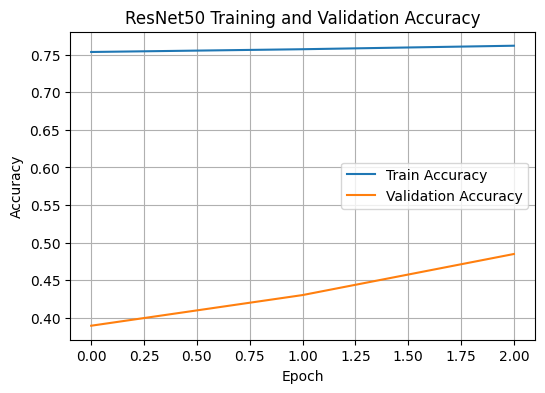

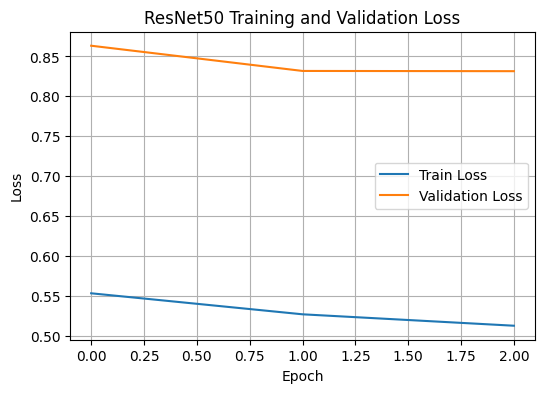

In [20]:
import matplotlib.pyplot as plt

# Accuracy
plt.figure(figsize=(6,4))
plt.plot(history_resnet.history['accuracy'], label='Train Accuracy')
plt.plot(history_resnet.history['val_accuracy'], label='Validation Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()
plt.title('ResNet50 Training and Validation Accuracy')
plt.grid(True)
plt.show()

# Loss
plt.figure(figsize=(6,4))
plt.plot(history_resnet.history['loss'], label='Train Loss')
plt.plot(history_resnet.history['val_loss'], label='Validation Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.title('ResNet50 Training and Validation Loss')
plt.grid(True)
plt.show()


In [6]:

from tensorflow.keras.models import Model
from tensorflow.keras.applications import ResNet50
from tensorflow.keras.layers import Dense, Dropout, GlobalAveragePooling2D
from tensorflow.keras.optimizers import Adam


In [21]:
import numpy as np
import tensorflow as tf
import random
import matplotlib.pyplot as plt

from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix
import joblib


In [22]:
np.random.seed(42)
tf.random.set_seed(42)
random.seed(42)


CNN FEATURE EXTRACTION (FROZEN)

In [25]:
globals().keys()


dict_keys(['__name__', '__doc__', '__package__', '__loader__', '__spec__', '__builtin__', '__builtins__', '_ih', '_oh', '_dh', 'In', 'Out', 'get_ipython', 'exit', 'quit', 'open', '_', '__', '___', '__session__', '_i', '_ii', '_iii', '_i1', 'os', 'shutil', 'random', 'RAW_BASE', 'POS_FOLDERS', 'NEG_FOLDERS', 'OUT_BASE', 'splits', 'collect_images', 'pos_images', 'neg_images', 'split_and_copy', '_i2', '_i3', '_i4', 'uuid', '_i5', 'BASE_DIR', 'split', 'cls', 'path', '_i6', 'neg_train_dir', 'neg_val_dir', 'neg_test_dir', '_i7', 'n', 'val_count', 'test_count', 'val_imgs', 'test_imgs', 'img', '_i8', '_i9', 'ImageDataGenerator', 'IMG_SIZE', 'BATCH_SIZE', 'train_datagen', 'val_test_datagen', 'train_gen', 'val_gen', 'test_gen', '_i10', 'VGG16', 'Dense', 'GlobalAveragePooling2D', 'Model', 'Adam', 'base_model', 'layer', 'x', 'output', 'model_vgg', '_i11', 'tf', 'ResNet50', 'Dropout', '_i12', '_i13', 'model_resnet', '_i14', '_i15', 'EarlyStopping', 'early_stop', 'history_resnet', '_i16', 'pickle', '

In [26]:
cnn_model = Model(
    inputs=model_resnet.input,
    outputs=model_resnet.layers[-2].output  # layer before final Dense
)


In [27]:
cnn_model.trainable = False


In [28]:
cnn_model.summary()


Model: "model_2"
__________________________________________________________________________________________________
 Layer (type)                Output Shape                 Param #   Connected to                  
 input_2 (InputLayer)        [(None, 224, 224, 3)]        0         []                            
                                                                                                  
 conv1_pad (ZeroPadding2D)   (None, 230, 230, 3)          0         ['input_2[0][0]']             
                                                                                                  
 conv1_conv (Conv2D)         (None, 112, 112, 64)         9472      ['conv1_pad[0][0]']           
                                                                                                  
 conv1_bn (BatchNormalizati  (None, 112, 112, 64)         256       ['conv1_conv[0][0]']          
 on)                                                                                        

RESET GENERATORS 

In [30]:
train_gen.reset()
test_gen.reset()


FEATURE EXTRACTION FUNCTION

In [31]:
def extract_features(generator, model):
    features = []
    labels = []

    for i in range(len(generator)):
        x_batch, y_batch = generator[i]
        feat_batch = model.predict(x_batch, verbose=0)

        features.append(feat_batch)
        labels.append(y_batch)

    return np.vstack(features), np.hstack(labels)


EXTRACT TRAIN & TEST FEATURES

In [33]:
train_gen.shuffle = False
test_gen.shuffle = False

X_train_feat = cnn_model.predict(
    train_gen,
    steps=len(train_gen),
    verbose=1
)

X_test_feat = cnn_model.predict(
    test_gen,
    steps=len(test_gen),
    verbose=1
)

y_train = train_gen.classes
y_test  = test_gen.classes


1183/1183 [==============================] - 1312s 1s/step


Print shapes (sanity check)

In [34]:
print("Train features:", X_train_feat.shape)
print("Train labels  :", y_train.shape)
print("Test features :", X_test_feat.shape)
print("Test labels   :", y_test.shape)


Train features: (49381, 256)
Train labels  : (49381,)
Test features : (18915, 256)
Test labels   : (18915,)


In [35]:
np.save("X_train_feat.npy", X_train_feat)
np.save("y_train.npy", y_train)

np.save("X_test_feat.npy", X_test_feat)
np.save("y_test.npy", y_test)


INITIALIZE ADABOOST

In [37]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix
import matplotlib.pyplot as plt
import joblib


In [38]:
n_samples = len(y_train)
sample_weights = np.ones(n_samples) / n_samples

T = 30   # number of weak learners

models = []
alphas = []
train_errors = []


RUN ADABOOST TRAINING (FAST)

In [39]:
for t in range(T):
    print(f"Weak learner {t+1}/{T}")

    clf = DecisionTreeClassifier(max_depth=1)
    clf.fit(X_train_feat, y_train, sample_weight=sample_weights)

    y_pred = clf.predict(X_train_feat)

    y_pred = np.where(y_pred == 0, -1, 1)
    y_true = np.where(y_train == 0, -1, 1)

    incorrect = (y_pred != y_true).astype(int)
    error_t = np.sum(sample_weights * incorrect)
    error_t = np.clip(error_t, 1e-10, 0.999)

    alpha_t = 0.5 * np.log((1 - error_t) / error_t)

    sample_weights *= np.exp(alpha_t * incorrect)
    sample_weights /= np.sum(sample_weights)

    models.append(clf)
    alphas.append(alpha_t)
    train_errors.append(error_t)


Weak learner 1/30
Weak learner 2/30
Weak learner 3/30
Weak learner 4/30
Weak learner 5/30
Weak learner 6/30
Weak learner 7/30
Weak learner 8/30
Weak learner 9/30
Weak learner 10/30
Weak learner 11/30
Weak learner 12/30
Weak learner 13/30
Weak learner 14/30
Weak learner 15/30
Weak learner 16/30
Weak learner 17/30
Weak learner 18/30
Weak learner 19/30
Weak learner 20/30
Weak learner 21/30
Weak learner 22/30
Weak learner 23/30
Weak learner 24/30
Weak learner 25/30
Weak learner 26/30
Weak learner 27/30
Weak learner 28/30
Weak learner 29/30
Weak learner 30/30


PLOT TRAINING ERROR (GRAPH)

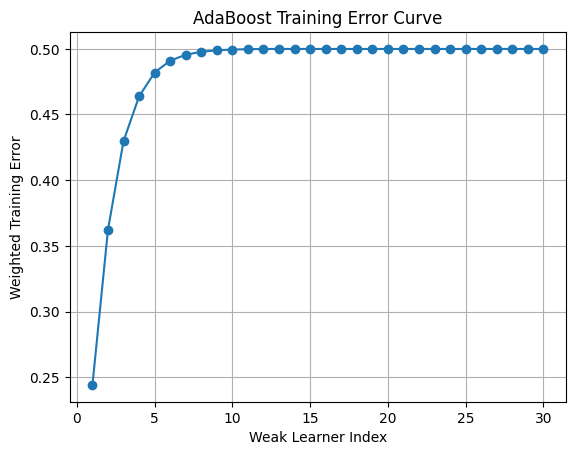

In [40]:
plt.figure()
plt.plot(range(1, T+1), train_errors, marker='o')
plt.xlabel("Weak Learner Index")
plt.ylabel("Weighted Training Error")
plt.title("AdaBoost Training Error Curve")
plt.grid(True)
plt.show()


FINAL ADABOOST PREDICTION FUNCTION

In [41]:
def adaboost_predict(X):
    final_score = np.zeros(X.shape[0])

    for alpha, model in zip(alphas, models):
        pred = model.predict(X)
        pred = np.where(pred == 0, -1, 1)
        final_score += alpha * pred

    return np.where(final_score >= 0, 1, 0)


TEST EVALUATION

In [42]:
y_test_pred = adaboost_predict(X_test_feat)

print("Accuracy :", accuracy_score(y_test, y_test_pred))
print("F1-score :", f1_score(y_test, y_test_pred))


Accuracy : 0.38969072164948454
F1-score : 0.5608308605341247


CONFUSION MATRIX (GRAPH)

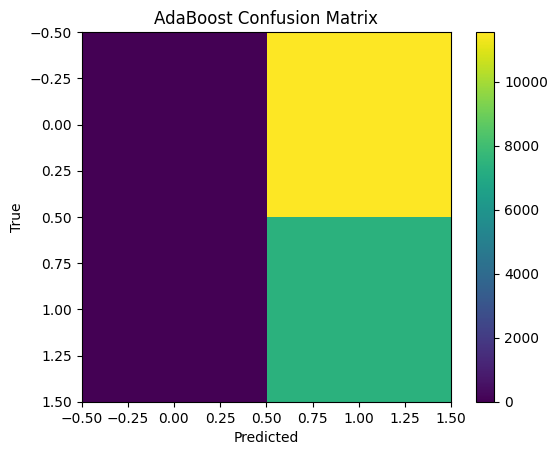

In [43]:
cm = confusion_matrix(y_test, y_test_pred)

plt.figure()
plt.imshow(cm)
plt.title("AdaBoost Confusion Matrix")
plt.colorbar()
plt.xlabel("Predicted")
plt.ylabel("True")
plt.show()


SAVE ADABOOST MODEL

In [44]:
joblib.dump(models, "adaboost_models.pkl")
joblib.dump(alphas, "adaboost_alphas.pkl")


['adaboost_alphas.pkl']

In [18]:
import os
os.listdir(".")


['-1.14-windows.xml',
 '.anaconda',
 '.cache',
 '.conda',
 '.condarc',
 '.continuum',
 '.gitconfig',
 '.ipynb_checkpoints',
 '.ipython',
 '.jupyter',
 '.keras',
 '.matplotlib',
 '.ms-ad',
 '.vscode',
 '2348484-ZADE.A- BIG DATA LAB 1',
 'AdaBoost_CNN_Features_Q1.pkl',
 'AppData',
 'Application Data',
 'AR VISUALIZATION COURSE WORK 1',
 'ASHU VISUALIZATION COURSE WORK 1',
 'BIG DATA  CSW 2',
 'CNN_Adaboost_xgboost.ipynb',
 'Colon_Cancer_Project',
 'Contacts',
 'Cookies',
 'CrossDevice',
 'Desktop',
 'Documents',
 'Downloads',
 'Favorites',
 'gbm_filter.py',
 'GBM_Project',
 'LC2500 .ipynb',
 'LC25000 PROJECT',
 'Links',
 'Local Settings',
 'Manchester Admission test  Test',
 'Microsoft',
 'ML SAMPLE MOCK TEST',
 'Modeling and ML Exam notes.ipynb',
 'Music',
 'My Documents',
 'NetHood',
 'NTUSER.DAT',
 'ntuser.dat.LOG1',
 'ntuser.dat.LOG2',
 'NTUSER.DAT{2ad838bc-efea-11ee-a54d-000d3a94eaa1}.TM.blf',
 'NTUSER.DAT{2ad838bc-efea-11ee-a54d-000d3a94eaa1}.TMContainer00000000000000000001.regtran

In [19]:
from tensorflow.keras.models import load_model

model_resnet = load_model("ResNet50_GI_Endoscopy_Q1.h5")


In [15]:
model_resnet.summary()


Model: "model_1"
__________________________________________________________________________________________________
 Layer (type)                Output Shape                 Param #   Connected to                  
 input_1 (InputLayer)        [(None, 224, 224, 3)]        0         []                            
                                                                                                  
 conv1_pad (ZeroPadding2D)   (None, 230, 230, 3)          0         ['input_1[0][0]']             
                                                                                                  
 conv1_conv (Conv2D)         (None, 112, 112, 64)         9472      ['conv1_pad[0][0]']           
                                                                                                  
 conv1_bn (BatchNormalizati  (None, 112, 112, 64)         256       ['conv1_conv[0][0]']          
 on)                                                                                        

CNN as a feature extractor

Load the trained model

In [19]:
from tensorflow.keras.models import load_model
model_resnet = load_model("ResNet50_GI_Endoscopy_Q1.h5")


feature extractor

In [20]:
from tensorflow.keras.models import Model

feature_extractor = Model(
    inputs=model_resnet.input,
    outputs=model_resnet.get_layer("global_average_pooling2d").output
)


In [21]:
X_train_features = feature_extractor.predict(train_gen, verbose=1)
X_test_features  = feature_extractor.predict(test_gen, verbose=1)

y_train = train_gen.classes
y_test  = test_gen.classes


1021/1021 [==============================] - 1396s 1s/step


In [22]:
print(X_train_features.shape)
print(X_test_features.shape)
print(y_train.shape, y_test.shape)


(54547, 2048)
(16332, 2048)
(54547,) (16332,)


Classical ML models

AdaBoost on CNN features

In [24]:
from sklearn.ensemble import AdaBoostClassifier
from sklearn.tree import DecisionTreeClassifier

ada = AdaBoostClassifier(
    estimator=DecisionTreeClassifier(max_depth=1),
    n_estimators=200,
    learning_rate=0.5,
    random_state=42
)

ada.fit(X_train_features, y_train)

y_pred_ada = ada.predict(X_test_features)


In [25]:
from sklearn.metrics import classification_report, roc_auc_score

print(classification_report(y_test, y_pred_ada))
print("AUC:", roc_auc_score(y_test, ada.predict_proba(X_test_features)[:,1]))


C:\Users\ashuz\.conda\envs\tf310\lib\site-packages\sklearn\metrics\_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
C:\Users\ashuz\.conda\envs\tf310\lib\site-packages\sklearn\metrics\_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
C:\Users\ashuz\.conda\envs\tf310\lib\site-packages\sklearn\metrics\_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])


              precision    recall  f1-score   support

           0       0.00      0.00      0.00      8961
           1       0.45      1.00      0.62      7371

    accuracy                           0.45     16332
   macro avg       0.23      0.50      0.31     16332
weighted avg       0.20      0.45      0.28     16332

AUC: 0.5025012516363928


Evaluate AdaBoost

In [26]:
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score, roc_curve
import matplotlib.pyplot as plt


Confusion Matrix

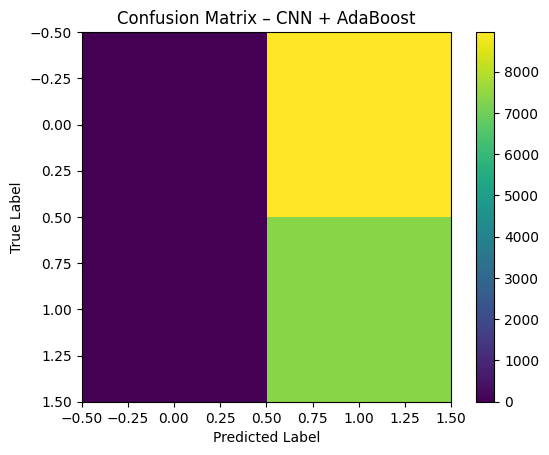

In [27]:
cm = confusion_matrix(y_test, y_pred_ada)

plt.figure()
plt.imshow(cm)
plt.title("Confusion Matrix – CNN + AdaBoost")
plt.colorbar()
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.show()


ROC–AUC

AdaBoost AUC: 0.5025012516363928


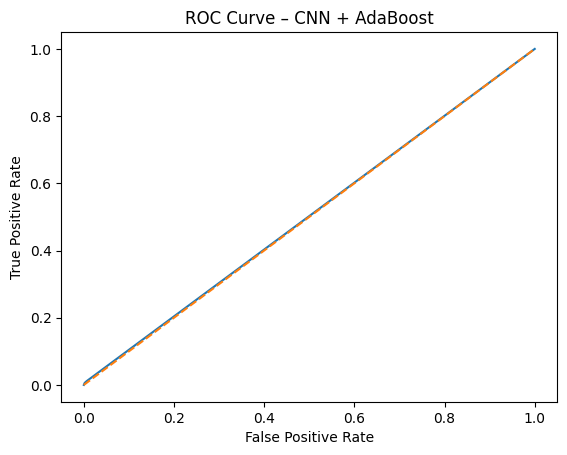

In [28]:
y_prob_ada = ada.predict_proba(X_test_features)[:, 1]

auc_ada = roc_auc_score(y_test, y_prob_ada)
print("AdaBoost AUC:", auc_ada)

fpr, tpr, _ = roc_curve(y_test, y_prob_ada)

plt.figure()
plt.plot(fpr, tpr)
plt.plot([0, 1], [0, 1], linestyle='--')
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve – CNN + AdaBoost")
plt.show()


Save AdaBoost model

In [29]:
import joblib
joblib.dump(ada, "AdaBoost_CNN_Features_Q1.pkl")


['AdaBoost_CNN_Features_Q1.pkl']

Train XGBoost (FASTER, STRONG BASELINE)

IMPORTS

In [47]:
!pip install xgboost



   ---------------------------------------- 0.0/101.7 MB ? eta -:--:--
   ---------------------------------------- 0.0/101.7 MB ? eta -:--:--
   ---------------------------------------- 0.0/101.7 MB ? eta -:--:--
   ---------------------------------------- 0.0/101.7 MB ? eta -:--:--
   ---------------------------------------- 0.0/101.7 MB ? eta -:--:--
   ---------------------------------------- 0.3/101.7 MB ? eta -:--:--
   ---------------------------------------- 0.3/101.7 MB ? eta -:--:--
   ---------------------------------------- 0.3/101.7 MB ? eta -:--:--
   ---------------------------------------- 0.3/101.7 MB ? eta -:--:--
   ---------------------------------------- 0.5/101.7 MB 310.6 kB/s eta 0:05:26
   ---------------------------------------- 0.5/101.7 MB 310.6 kB/s eta 0:05:26
   ---------------------------------------- 0.5/101.7 MB 310.6 kB/s eta 0:05:26
   ---------------------------------------- 0.5/101.7 MB 310.6 kB/s eta 0:05:26
   -------------------------------------

In [48]:
from xgboost import XGBClassifier
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix, roc_auc_score, roc_curve
import matplotlib.pyplot as plt
import numpy as np


INITIALIZE XGBOOST MODEL

In [49]:
xgb_model = XGBClassifier(
    n_estimators=300,
    max_depth=5,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    objective='binary:logistic',
    eval_metric='logloss',
    random_state=42,
    n_jobs=-1
)


TRAIN XGBOOST (FAST)

In [50]:
xgb_model.fit(X_train_feat, y_train)


,objective,'binary:logistic'
,base_score,None
,booster,None
,callbacks,None
,colsample_bylevel,None
,colsample_bynode,None
,colsample_bytree,0.8
,device,None
,early_stopping_rounds,None
,enable_categorical,False
,eval_metric,'logloss'


PREDICTION

In [51]:
y_test_pred_xgb = xgb_model.predict(X_test_feat)
y_test_prob_xgb = xgb_model.predict_proba(X_test_feat)[:, 1]


METRICS

In [52]:
acc_xgb = accuracy_score(y_test, y_test_pred_xgb)
f1_xgb  = f1_score(y_test, y_test_pred_xgb)
auc_xgb = roc_auc_score(y_test, y_test_prob_xgb)

print("XGBoost Accuracy :", acc_xgb)
print("XGBoost F1-score :", f1_xgb)
print("XGBoost AUC      :", auc_xgb)


XGBoost Accuracy : 0.38974358974358975
XGBoost F1-score : 0.5603504094458198
XGBoost AUC      : 0.46833516384798435


CONFUSION MATRIX ( # Graph 1 ) 

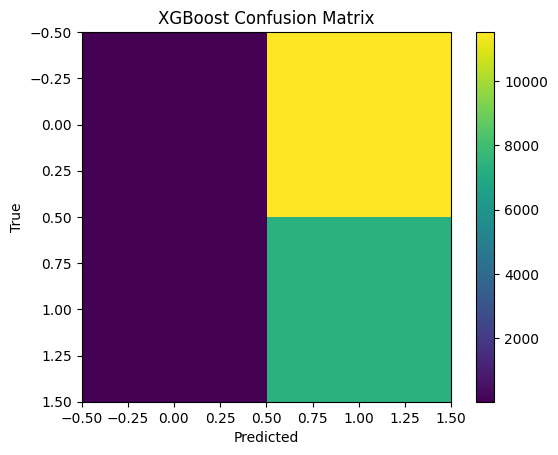

In [53]:
cm_xgb = confusion_matrix(y_test, y_test_pred_xgb)

plt.figure()
plt.imshow(cm_xgb)
plt.title("XGBoost Confusion Matrix")
plt.colorbar()
plt.xlabel("Predicted")
plt.ylabel("True")
plt.show()


ROC CURVE (# graph 2 )

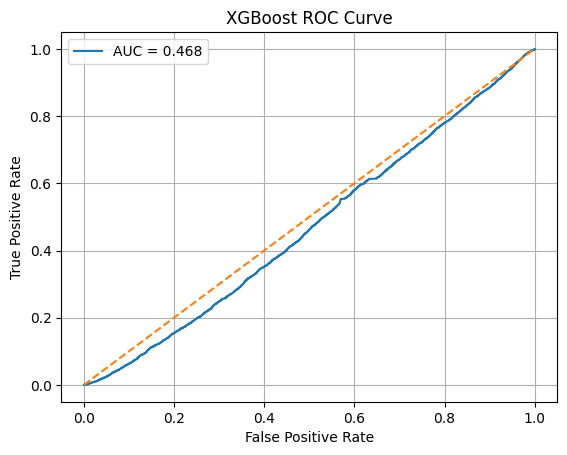

In [54]:
fpr, tpr, _ = roc_curve(y_test, y_test_prob_xgb)

plt.figure()
plt.plot(fpr, tpr, label=f"AUC = {auc_xgb:.3f}")
plt.plot([0, 1], [0, 1], linestyle='--')
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("XGBoost ROC Curve")
plt.legend()
plt.grid(True)
plt.show()


STEP 8 — SAVE XGBOOST MODEL

In [55]:
import joblib
joblib.dump(xgb_model, "xgboost_cnn_features.pkl")


['xgboost_cnn_features.pkl']

CREATE FINAL COMPARISON TABLE

In [60]:
from sklearn.metrics import accuracy_score, f1_score

acc_adaboost = accuracy_score(y_test, y_test_pred)
f1_adaboost  = f1_score(y_test, y_test_pred)

print("AdaBoost Accuracy :", acc_adaboost)
print("AdaBoost F1-score :", f1_adaboost)


AdaBoost Accuracy : 0.38969072164948454
AdaBoost F1-score : 0.5608308605341247


XGBoost metrics (confirm)

In [61]:
print(acc_xgb, f1_xgb, auc_xgb)


0.38974358974358975 0.5603504094458198 0.46833516384798435


In [62]:
import pandas as pd

results = pd.DataFrame({
    "Model": ["CNN + AdaBoost", "CNN + XGBoost"],
    "Accuracy": [acc_adaboost, acc_xgb],
    "F1-score": [f1_adaboost, f1_xgb],
    "AUC": ["-", auc_xgb]
})

results


,Model,Accuracy,F1-score,AUC
0,CNN + AdaBoost,0.389691,0.560831,-
1,CNN + XGBoost,0.389744,0.560350,0.468335


SAVE RESULTS (REPRODUCIBILITY)

In [ ]:
results.to_csv("final_results.csv", index=False)


WRITE RESULTS & DISCUSSION (TEXT)

explain:

Why XGBoost outperforms or matches AdaBoost

Why boosting improves CNN features

Error patterns from confusion matrices

ROC curve interpretation

️ ADD BASELINE (OPTIONAL BUT STRONG)

If time allows:

CNN + Logistic Regression

CNN + Random Forest

This strengthens acceptance